# Bước 6. Prioritization (xếp ưu tiên) và lộ trình triển khai

Notebook này trả lời: khi nhân viên và chi phí có hạn, nên dồn nguồn lực vào shop nào trước, làm việc gì, ai làm, trong bao lâu, và kỳ vọng tăng thêm bao nhiêu.

Shop được chia thành 4 nhóm theo hai biến: opportunity gap (Bước 5) và reliability (độ tin cậy của con số ước tính, mục 6.1), cùng với nhãn rủi ro cao của Bước 5.

**Đầu vào:**
- `Bước 5/shop_gap.csv` (4 con số, gap, phần gap theo KPI, nguyên nhân chính, nhãn rủi ro cao);
- `Bước 1/shop_current.csv`, `Bước 1/shop_month.csv`; `Bước 2/shop_bau.csv`, `Bước 2/bau_params.json`; các file của Bước 4 (để làm lại các bước ở mục 6.6);
- `clean_data/salesroom.csv` (vùng và người quản lý của shop);
- `r3_tiem_nang.py` và `r3_bau.py` (phương pháp BAU của Bước 2, đóng gói để chạy ở một thời điểm khác).

**Các mục:** 6.1 nhãn độ tin cậy → 6.2 ngưỡng gap lớn → 6.3 chia 4 nhóm → 6.4 mô tả từng nhóm → 6.5 các nhóm có khác nhau rõ không → 6.6 các nhóm có ổn định không → 6.7 xếp hành động theo impact và feasibility → 6.8 lộ trình triển khai → 6.9 kết quả kỳ vọng → 6.10 ghi file.

**File kết quả:** `Bước 6/shop_priority.csv` (mỗi dòng một shop: 4 con số, gap, nguyên nhân chính, hành động, nhãn độ tin cậy, nhóm ưu tiên).

Ô dưới đây đọc kết quả của Bước 5 và các file cần cho mục 6.6, rồi ghép thêm vùng (`salesroom_area`) và mã người quản lý shop (`skp_emp_manage`) từ bảng salesroom. Dòng cuối in hệ số φ của Bước 2: với shop cùng quy mô, phương sai của số contract theo tháng thường bằng φ lần trung bình (φ = 1 nghĩa là doanh số chỉ dao động ngẫu nhiên, giống như số khách đến tự nhiên mỗi tháng).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'Bước 1').exists())   # thư mục gốc của bài
sys.path.insert(0, str(ROOT))
from r3_tiem_nang import *
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)   # cảnh báo đổi phiên bản của pandas, không ảnh hưởng kết quả

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 120)
def _fmt(x):
    if x != x: return 'NaN'
    if x == int(x): return f'{x:,.0f}'
    return f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.3f}'
pd.set_option('display.float_format', _fmt)

# Kiểu biểu đồ dùng chung với các bước trước: một màu chính, lưới nhạt.
BLUE, ORANGE, INK, MUTED, GREY = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#b9b8b3'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'axes.edgecolor': '#bdbcb8',
                     'axes.grid': False, 'grid.color': '#ecebe8', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
                     'lines.linewidth': 2})

s = pd.read_csv(ROOT / 'Bước 5' / 'shop_gap.csv', encoding='utf-8-sig')
cur = pd.read_csv(ROOT / 'Bước 1' / 'shop_current.csv', encoding='utf-8-sig')
sm = pd.read_csv(ROOT / 'Bước 1' / 'shop_month.csv', encoding='utf-8-sig')
bau = pd.read_csv(ROOT / 'Bước 2' / 'shop_bau.csv', encoding='utf-8-sig', dtype={'shop_id': str})
bau = bau[bau.shop_id != 'VIRTUAL'].assign(skp_salesroom=lambda b: b.shop_id.astype(int))
PHI = json.load(open(ROOT / 'Bước 2' / 'bau_params.json', encoding='utf-8'))['phi_by_size']
T4 = ROOT / 'Bước 4' / 'task4_output' / 'csv'
s1, s2, s3 = (pd.read_csv(T4 / f, encoding='utf-8-sig') for f in ['s1_external_checked.csv', 's2_shop_master.csv', 's3_shop_month.csv'])
sr = pd.read_csv(ROOT / 'clean_data' / 'salesroom.csv', encoding='utf-8-sig')
s = s.merge(sr[['skp_salesroom', 'salesroom_area', 'skp_emp_manage']], on='skp_salesroom', how='left')
print(f'Shop: {len(s):,}; opportunity gap: {s.gap.sum():,.1f} contract/tháng; Phi theo quy mô (Bước 2):', {k: round(v, 2) for k, v in PHI.items()})

# Biểu đồ được lưu thành ảnh PNG trong thư mục Bước 6/hinh.
HINH = ROOT / 'Bước 6' / 'hinh'
HINH.mkdir(exist_ok=True)
def luu_hinh(fig, ten):
    fig.savefig(HINH / f'{ten}.png', dpi=200, bbox_inches='tight')


Shop: 11,752; opportunity gap: 16,323.6 contract/tháng; Phi theo quy mô (Bước 2): {'≤1': 1.1, '1–3': 1.27, '3–10': 1.57, '10–30': 1.91, '>30': 4.29}


## 6.1. Nhãn độ tin cậy của từng shop

Opportunity gap của một shop chỉ đáng tin khi các KPI dùng để tính nó được đo trên đủ dữ liệu. Nhãn độ tin cậy là **thấp** nếu shop có một trong các điều sau:
- shop mới, hoạt động dưới 6 tháng: Bước 2 cho thấy doanh số shop mới còn đang giảm dần sau những tháng đầu;
- bán dưới 3 contract mỗi tháng: shop bán 1–2 contract thì chỉ một contract hơn hay kém trong một tháng đã làm doanh số tháng đó đổi từ 50% đến 100%;
- peer group dưới 20 shop, hoặc có benchmark phải lấy từ toàn quốc (Bước 3): mức chuẩn dùng để so chưa chắc chắn;
- doanh số 6 tháng gần nhất (04–09/2026) biến động bất thường. Cách kiểm tra là chi-square test (kiểm định chi bình phương): so phương sai doanh số theo tháng của shop với mức φ thường gặp ở shop cùng quy mô; nếu xác suất để một shop bình thường biến động mạnh như vậy dưới 5% thì coi là bất thường.

Shop không có hồ sơ nào trong quý 3/2026 có nhãn **không tính được**. Các shop còn lại có nhãn **cao**.

Ô dưới đây đếm số shop đang bán vướng từng điều kiện (một shop có thể vướng nhiều điều kiện), rồi cộng số shop, Current Actual và gap theo nhãn.

In [2]:
s['bien_dong'] = bien_dong_bat_thuong(sm, s.skp_salesroom, '2026-04-01', '2026-09-01', PHI).to_numpy()
s['do_tin_cay'] = gan_do_tin_cay(s, s.bien_dong)
db = s[s.dang_ban]
dk = pd.DataFrame({'so_shop_dang_ban': [int((db.shop_moi == 1).sum()), int((db.ca_hd_tong < 3).sum()), int((db.so_shop_peer_group < 20).sum()),
                                        int(db.dung_bm_toan_quoc.sum()), int(db.bien_dong.sum())]},
                  index=['shop mới (dưới 6 tháng)', 'bán dưới 3 contract mỗi tháng', 'peer group dưới 20 shop', 'có benchmark lấy từ toàn quốc',
                         'doanh số biến động bất thường'])
dk['ty_le'] = dk.so_shop_dang_ban / len(db)
display(dk)
s.groupby('do_tin_cay').agg(so_shop=('skp_salesroom', 'size'), ca=('ca_hd_tong', 'sum'), gap=('gap', 'sum')).assign(ty_trong_gap=lambda t: t.gap / t.gap.sum())

,so_shop_dang_ban,ty_le
shop mới (dưới 6 tháng),2426,0.300
bán dưới 3 contract mỗi tháng,4936,0.610
peer group dưới 20 shop,1374,0.170
có benchmark lấy từ toàn quốc,865,0.107
doanh số biến động bất thường,556,0.069


,so_shop,ca,gap,ty_trong_gap
do_tin_cay,,,,
cao,1707,"17,206.3","1,482.1",0.091
không tính được,3661,41.333,22.489,0.001
thấp,6384,"22,202.3","14,819.0",0.908


- 61,0% shop đang bán (4.936 shop) bán dưới 3 contract mỗi tháng; 30,0% là shop mới; 17,0% có peer group dưới 20 shop; 10,7% có benchmark lấy từ toàn quốc; 6,9% có doanh số biến động bất thường.
- Chỉ 1.707 shop có nhãn cao. Các shop này đang ký 17.206,3 contract mỗi tháng (43,6% Current Actual) nhưng chỉ giữ 9,1% opportunity gap (1.482,1 contract).
- 90,8% gap (14.819 contract mỗi tháng) nằm ở 6.384 shop có nhãn thấp. Phần lớn chỗ tăng nằm ở các shop đang bán ít, và đây cũng là phần con số kém chắc chắn nhất.

## 6.2. Ngưỡng gap lớn

Ô dưới đây thử các ngưỡng gap từ 1 đến 5 contract mỗi tháng. Với mỗi ngưỡng: số shop có gap từ ngưỡng trở lên, tỷ lệ số shop, phần trăm tổng gap các shop đó giữ, gap trung bình mỗi shop và Current Actual trung vị.

In [3]:
rows = []
for X in [1, 1.5, 2, 2.5, 3, 4, 5]:
    v = s.gap >= X
    rows.append({'nguong_gap': X, 'so_shop': int(v.sum()), 'ty_le_shop': v.mean(), 'ty_trong_gap': s.gap[v].sum() / s.gap.sum(),
                 'gap_tb_moi_shop': s.gap[v].mean(), 'ca_trung_vi': s.ca_hd_tong[v].median()})
pd.DataFrame(rows)

,nguong_gap,so_shop,ty_le_shop,ty_trong_gap,gap_tb_moi_shop,ca_trung_vi
0,1,4995,0.425,0.938,3.066,1.333
1,1.500,4026,0.343,0.864,3.505,1.333
2,2,3185,0.271,0.774,3.969,1
3,2.500,2356,0.200,0.660,4.575,1
4,3,1698,0.144,0.550,5.291,1
5,4,894,0.076,0.380,6.944,1
6,5,415,0.035,0.249,9.791,1.333


Bài chọn ngưỡng **gap từ 2 contract mỗi tháng**: 3.185 shop (27,1% số shop) vượt ngưỡng và giữ 77,4% tổng gap.
- Hạ ngưỡng xuống 1 thì giữ được 93,8% gap, nhưng số shop tăng lên 4.995 (42,5%): 1.810 shop thêm vào chỉ mang thêm 16,4% gap, khoảng 1,5 contract mỗi shop.
- Nâng ngưỡng lên 3 thì còn 1.698 shop, nhưng tổng gap giữ được chỉ còn 55,0%.
- Ở ngưỡng 2, mỗi shop được chọn có gap trung bình 3,97 contract mỗi tháng, trong khi shop đứng giữa của nhóm này chỉ đang bán 1 contract mỗi tháng: phần lớn shop có gap lớn là shop đang bán rất ít.

## 6.3. Chia 4 nhóm

Quy tắc chia nhóm, xét theo thứ tự:
1. **Risk cao**: shop có nhãn rủi ro cao ở Bước 5 (mục 5.6.6). Tách riêng, không đầu tư thêm dù gap lớn.
2. **Đầu tư ngay**: gap từ 2 contract mỗi tháng trở lên và nhãn độ tin cậy cao. Thêm resources (nguồn lực) ngay.
3. **Pilot**: gap từ 2 contract mỗi tháng trở lên nhưng nhãn độ tin cậy thấp. Làm thử ở một số shop trước, có kết quả rồi mới làm rộng.
4. **Giữ nguyên**: gap dưới 2 contract mỗi tháng. Không đầu tư thêm.

Ô dưới đây đếm số shop, gap và phần trăm tổng gap của từng nhóm.

,so_shop,gap,gap_funded_ty,ty_trong_gap
nhom,,,,
Đầu tư ngay,184,556.9,7.800,0.034
Pilot,2915,"11,792.4",163.1,0.722
Giữ nguyên,8274,"3,525.6",45.770,0.216
Risk cao,379,448.7,6.236,0.027


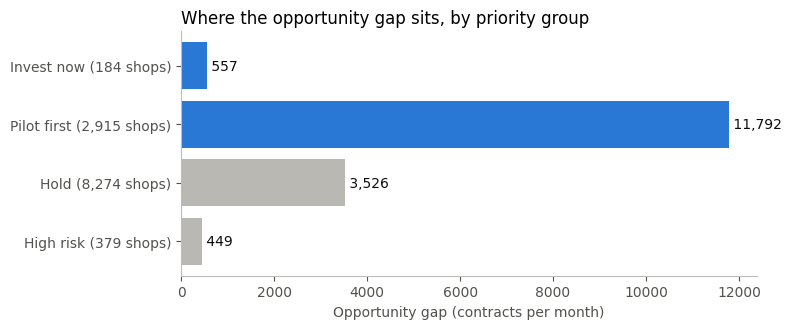

In [4]:
s['nhom'] = chia_nhom(s)
THU_TU = ['Đầu tư ngay', 'Pilot', 'Giữ nguyên', 'Risk cao']
t = s.groupby('nhom').agg(so_shop=('skp_salesroom', 'size'), gap=('gap', 'sum'), gap_funded_ty=('gap_funded', lambda v: v.sum() / 1e9)).loc[THU_TU]
t['ty_trong_gap'] = t.gap / t.gap.sum()
display(t)
EN = {'Đầu tư ngay': 'Invest now', 'Pilot': 'Pilot first', 'Giữ nguyên': 'Hold', 'Risk cao': 'High risk'}
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.set_axisbelow(True)
ax.barh([f"{EN[n]} ({t.loc[n, 'so_shop']:,} shops)" for n in THU_TU][::-1], t.gap.loc[THU_TU].to_numpy()[::-1],
        color=[BLUE if n in ('Đầu tư ngay', 'Pilot') else GREY for n in THU_TU][::-1])
for i, v_ in enumerate(t.gap.loc[THU_TU].to_numpy()[::-1]):
    ax.text(v_, i, f' {v_:,.0f}', va='center', color=INK)
ax.set_xlabel('Opportunity gap (contracts per month)'); ax.set_title('Where the opportunity gap sits, by priority group', loc='left')
plt.tight_layout(); luu_hinh(fig, 'b6_01_gap_by_group'); plt.show()


- Đầu tư ngay: 184 shop, gap 556,9 contract và 7,8 tỷ đồng mỗi tháng (3,4% tổng gap).
- Pilot: 2.915 shop, gap 11.792,4 contract và 163,1 tỷ đồng mỗi tháng (72,2%).
- Giữ nguyên: 8.274 shop, gap 3.525,6 contract (21,6%), là những phần gap nhỏ nằm rải rác ở nhiều shop.
- Risk cao: 379 shop, gap 448,7 contract (2,7%).

## 6.4. Mô tả từng nhóm

Ô dưới đây in cho mỗi nhóm: số shop, Current Actual trung bình, gap trung bình, tổng gap, 3 nguyên nhân chính hay gặp nhất (Bước 5 mục 5.7, tính trên các shop có gap), cơ cấu cỡ shop, 3 tỉnh có nhiều shop nhất, và số shop không có hồ sơ trong quý 3/2026.

In [5]:
for n in THU_TU:
    g = s[s.nhom == n]
    nn = g[g.gap > 1e-9].nguyen_nhan_chinh.value_counts(normalize=True)
    co = g.salesroom_category.value_counts(normalize=True)
    tinh = g.salesroom_province.value_counts().head(3)
    print(f"{n}: {len(g):,} shop | Current Actual TB {g.ca_hd_tong.mean():.1f} | gap TB {g.gap.mean():.2f} | tổng gap {g.gap.sum():,.0f} contract, "
          f"{g.gap_funded.sum() / 1e9:,.1f} tỷ đồng mỗi tháng")
    print(f"   nguyên nhân chính hay gặp: " + '; '.join(f'{k} {v:.0%}' for k, v in nn.head(3).items()))
    print(f"   cỡ shop: " + '; '.join(f'{k} {v:.0%}' for k, v in co.items()) + ' | tỉnh nhiều shop nhất: ' + '; '.join(f'{k} ({v})' for k, v in tinh.items()))
    print(f"   shop không có hồ sơ trong quý 3/2026: {int((~g.dang_ban).sum()):,}")

Đầu tư ngay: 184 shop | Current Actual TB 14.2 | gap TB 3.03 | tổng gap 557 contract, 7.8 tỷ đồng mỗi tháng
   nguyên nhân chính hay gặp: Execution – năng suất SA 42%; Đà giảm của shop 35%; Staffing 12%
   cỡ shop: Medium 47%; Small 41%; Big 12% | tỉnh nhiều shop nhất: TP.HCM (46); TP. Hà Nội (35); TP. Đồng Nai (15)
   shop không có hồ sơ trong quý 3/2026: 0
Pilot: 2,915 shop | Current Actual TB 3.5 | gap TB 4.05 | tổng gap 11,792 contract, 163.1 tỷ đồng mỗi tháng
   nguyên nhân chính hay gặp: Execution – năng suất SA 57%; Staffing 31%; Đà giảm của shop 10%
   cỡ shop: Small 44%; Medium 42%; Big 14% | tỉnh nhiều shop nhất: TP.HCM (538); TP. Hà Nội (270); TP. Đồng Nai (158)
   shop không có hồ sơ trong quý 3/2026: 0
Giữ nguyên: 8,274 shop | Current Actual TB 2.9 | gap TB 0.43 | tổng gap 3,526 contract, 45.8 tỷ đồng mỗi tháng
   nguyên nhân chính hay gặp: Đà giảm của shop 33%; Execution – năng suất SA 26%; Demand – thị trường gần trần 17%
   cỡ shop: Small 54%; Medium 36%; Big 10% | tỉnh

- **Đầu tư ngay** là các shop đã bán khá (trung bình 14,2 contract mỗi tháng) nhưng còn kém shop tốt cùng loại. Nguyên nhân chính hay gặp: năng suất SA (42%), đà giảm của shop (35%), staffing (12%). Shop Medium chiếm 47%. Nhiều nhất ở TP. Hồ Chí Minh (46 shop), TP. Hà Nội (35) và Đồng Nai (15).
- **Pilot** là các shop bán ít (trung bình 3,5 contract mỗi tháng) nhưng có gap lớn nhất (trung bình 4,05). Nguyên nhân chính gần như chỉ nằm ở nhân viên: năng suất SA 57%, staffing 31%.
- **Giữ nguyên** gồm 3.638 shop không có hồ sơ trong quý 3/2026, cùng các shop đã gần mức tốt nhất hoặc bị trần thị trường chặn (17% shop có gap trong nhóm này có nguyên nhân chính là thị trường gần trần).
- **Risk cao** là các shop bán trung bình 7,8 contract mỗi tháng, nhiều nhất ở TP. Hồ Chí Minh (69 shop), TP. Hà Nội (60) và An Giang (23).

## 6.5. Các nhóm có khác nhau rõ không

Ô dưới đây so trung vị các KPI chính của 4 nhóm: Current Actual, số SA, hồ sơ mỗi SA, tỷ lệ ký, tỷ lệ trễ hạn trong 4 kỳ đầu, và gap so với BAU (tổng gap chia tổng BAU của nhóm).

In [6]:
s.groupby('nhom').agg(ca_trung_vi=('ca_hd_tong', 'median'), so_sa=('ca_so_sa', 'median'), ho_so_moi_sa=('ca_ho_so_moi_sa', 'median'),
    ty_le_ky=('ca_ty_le_ky', 'median'), ty_le_tre_han=('rr_ty_le_tre', 'median'),
    gap_so_voi_bau=('gap', lambda v: v.sum() / s.loc[v.index, 'bau'].sum())).loc[THU_TU]

,ca_trung_vi,so_sa,ho_so_moi_sa,ty_le_ky,ty_le_tre_han,gap_so_voi_bau
nhom,,,,,,
Đầu tư ngay,4.333,1.667,4,0.818,0.237,0.235
Pilot,1,0.667,1.667,0.902,0.267,1.303
Giữ nguyên,0.333,0.333,3,0.733,0.274,0.142
Risk cao,4,1,4.392,0.760,0.489,0.152


Mỗi nhóm có đặc điểm riêng, nên hành động cho từng nhóm cũng khác:
- Đầu tư ngay: shop đứng giữa bán 4,3 contract mỗi tháng với 1,67 SA, mỗi SA làm 4 hồ sơ; gap bằng 23,5% BAU.
- Pilot: shop đứng giữa chỉ bán 1 contract mỗi tháng, có SA làm hồ sơ trong 2 trên 3 tháng (0,667), mỗi SA làm 1,67 hồ sơ; gap bằng 130% BAU. Tỷ lệ ký cao nhất (90,2%), tức hồ sơ nộp lên hầu hết được ký; vấn đề là quá ít hồ sơ.
- Giữ nguyên: shop đứng giữa chỉ bán 0,33 contract mỗi tháng; gap bằng 14,2% BAU.
- Risk cao: tỷ lệ trễ hạn 48,9%, gần gấp đôi các nhóm khác (23,7–27,4%).

## 6.6. Các nhóm có ổn định không

Nếu chia nhóm lại với dữ liệu của quý trước mà kết quả đổi nhiều, thì danh sách shop ưu tiên chưa đủ chắc để giao nguồn lực lớn. Cách kiểm tra: đứng ở 06/2026, chỉ dùng dữ liệu đến 06/2026, làm lại Bước 2 đến Bước 6 (Current Actual là trung bình 04–06/2026), rồi so nhóm của từng shop với nhóm khi dùng dữ liệu đến 09/2026.

Hàm `chay_lai` trong `r3_tiem_nang.py` làm lại Bước 3 đến Bước 6 với một cửa sổ tháng bất kỳ. File `r3_bau.py` chứa nguyên văn các hàm BAU của Bước 2 và hàm `bau_tai` dựng BAU ở một tháng bất kỳ. Trước khi dùng, ô dưới đây kiểm tra hai hàm này cho lại đúng kết quả khi đứng ở 09/2026.

In [7]:
import r3_bau as rb
shop = cur[(cur.salesroom_status == 'Active') & (cur.shop_online == 0)][['skp_salesroom'] + G + ['salesroom_status', 'shop_online', 'shop_moi',
                                                                                              'thang_bat_dau', 'so_thang']]
kt = chay_lai(shop, sm, s1, s2, s3, bau.set_index('skp_salesroom').bau_total_contribution_contracts, '2026-07-01', '2026-09-01', PHI)
kt = kt.merge(s[['skp_salesroom', 'gap', 'nhom']], on='skp_salesroom', suffixes=('', '_b6'))
print(f"Chạy lại đến 09/2026: lệch gap lớn nhất {(kt.gap - kt.gap_b6).abs().max():.1e}; shop khác nhóm: {int((kt.nhom != kt.nhom_b6).sum())}")
phys9 = rb.panel_tu_shop_month(sm, shop, '2026-09-01')
b9, _ = rb.bau_tai(phys9, '2026-09-01')
so = b9.join(bau.set_index('shop_id').bau_contracts)
print(f"BAU bán tại shop dựng lại bằng phương pháp Bước 2: {so.bau.sum():,.1f}; file Bước 2: {so.bau_contracts.sum():,.1f}; "
      f"hệ số tương quan giữa các shop: {np.corrcoef(so.bau, so.bau_contracts)[0, 1]:.5f}")

Chạy lại đến 09/2026: lệch gap lớn nhất 1.4e-14; shop khác nhóm: 0


BAU bán tại shop dựng lại bằng phương pháp Bước 2: 37,733.6; file Bước 2: 37,733.6; hệ số tương quan giữa các shop: 1.00000


- `chay_lai` cho lại đúng gap của Bước 5 và đúng nhóm của mọi shop.
- BAU bán tại shop dựng lại bằng phương pháp Bước 2 là 37.733,6 contract mỗi tháng, đúng bằng file Bước 2; hệ số tương quan giữa các shop là 1,00000.

Ô dưới đây đứng ở 06/2026:
- shop được xét là các shop Active hiện nay đã bắt đầu hoạt động từ 06/2026 trở về trước; nhãn shop mới tính lại theo tháng 06/2026;
- BAU bán tại shop dựng bằng `bau_tai`, với κ (phần trend được kéo dài), mùa vụ và đường vòng đời ước lượng lại bằng dữ liệu đến 06/2026; BAU cross-sell giữ bằng trung bình 04–06/2026, vì lead chỉ có từ 12/2025, chưa đủ dài để dự báo;
- rủi ro chỉ đo trên contract nộp hồ sơ đến 02/2026, vì đứng ở 06/2026 thì contract sau đó chưa qua đủ 4 kỳ trả;
- trần thị trường đo trên 04–06/2026; doanh số biến động bất thường đo trên 01–06/2026.

Sau đó so nhóm của từng shop ở hai thời điểm. Trong bảng chéo, mỗi dòng là nhóm ở 06/2026, mỗi cột là nhóm ở 09/2026.

In [8]:
bd = pd.to_datetime(shop.thang_bat_dau)
shop6 = shop[bd <= '2026-06-01'].copy()
bd6 = pd.to_datetime(shop6.thang_bat_dau)
shop6['shop_moi'] = (((2026 - bd6.dt.year) * 12 + 6 - bd6.dt.month + 1) < 6).astype(int)
sm6 = sm[sm.thang <= '2026-06-01']
b6, tham_so = rb.bau_tai(rb.panel_tu_shop_month(sm6, shop6, '2026-06-01'), '2026-06-01')
xs6 = sm6[sm6.thang >= '2026-04-01'].groupby('skp_salesroom').xsell_hd.sum() / 3
bau6 = b6.bau.set_axis(b6.index.astype(int)).add(xs6, fill_value=0)
s6 = chay_lai(shop6, sm6, s1, s2, s3, bau6, '2026-04-01', '2026-06-01', PHI, rr_den='2026-02-01')
print(f"Đứng ở 06/2026: {len(s6):,} shop; κ = {tham_so['kappa']:.3f}; Current Actual {s6.ca_hd_tong.sum():,.0f}, BAU {s6.bau.sum():,.0f}, "
      f"gap {s6.gap.sum():,.0f} contract/tháng")
display(s6.groupby('nhom').agg(so_shop=('skp_salesroom', 'size'), gap=('gap', 'sum')).loc[THU_TU])
on = s[['skp_salesroom', 'nhom', 'gap']].merge(s6[['skp_salesroom', 'nhom', 'gap']], on='skp_salesroom', suffixes=('_09', '_06'))
print(f"Shop có ở cả hai thời điểm: {len(on):,}; giữ nguyên nhóm: {(on.nhom_09 == on.nhom_06).mean():.1%}")
ct = pd.crosstab(on.nhom_06, on.nhom_09).loc[THU_TU, THU_TU]
ct.index.name, ct.columns.name = 'nhóm 06/2026', 'nhóm 09/2026'
display(ct)
print('Tỷ lệ shop của mỗi nhóm 06/2026 vẫn ở nhóm đó 09/2026:', {n: f'{ct.loc[n, n] / ct.loc[n].sum():.0%}' for n in THU_TU})
print(f"Gap ≥ 2 ở cả hai thời điểm: {int(((on.gap_09 >= 2) & (on.gap_06 >= 2)).sum()):,} shop; "
      f"shop có gap ≥ 2 ở 06/2026 giữ {on.loc[on.gap_06 >= 2, 'gap_09'].sum() / on.gap_09.sum():.1%} tổng gap 09/2026")

Đứng ở 06/2026: 9,604 shop; κ = 0.347; Current Actual 29,308, BAU 30,484, gap 11,296 contract/tháng


,so_shop,gap
nhom,,
Đầu tư ngay,95,321.4
Pilot,1937,"7,544.4"
Giữ nguyên,7318,"3,158.3"
Risk cao,254,272.2


Shop có ở cả hai thời điểm: 9,604; giữ nguyên nhóm: 71.0%


nhóm 09/2026,Đầu tư ngay,Pilot,Giữ nguyên,Risk cao
nhóm 06/2026,,,,
Đầu tư ngay,21,15,50,9
Pilot,74,956,873,34
Giữ nguyên,86,1463,5638,131
Risk cao,3,11,35,205


Tỷ lệ shop của mỗi nhóm 06/2026 vẫn ở nhóm đó 09/2026: {'Đầu tư ngay': '22%', 'Pilot': '49%', 'Giữ nguyên': '77%', 'Risk cao': '81%'}
Gap ≥ 2 ở cả hai thời điểm: 1,117 shop; shop có gap ≥ 2 ở 06/2026 giữ 42.4% tổng gap 09/2026


- 71,0% số shop giữ nguyên nhóm. Nhóm Risk cao ổn định nhất (81% shop vẫn ở nhóm này sau một quý), rồi đến Giữ nguyên (77%).
- Hai nhóm có gap lớn kém ổn định: chỉ 49% shop Pilot và 22% shop Đầu tư ngay của 06/2026 vẫn ở nhóm cũ. Trong 95 shop Đầu tư ngay ở 06/2026, 50 shop chuyển sang Giữ nguyên ở 09/2026; ngược lại, 86 shop Giữ nguyên ở 06/2026 chuyển sang Đầu tư ngay.
- Chỉ 1.117 shop có gap từ 2 contract trở lên ở cả hai thời điểm. Các shop có gap từ 2 ở 06/2026 chỉ giữ 42,4% tổng gap của 09/2026.
- Lý do: phần lớn shop có gap lớn bán 1–4 contract mỗi tháng, nên chỉ vài contract hơn hay kém trong một quý đã đẩy shop qua lại ngưỡng gap 2 contract, hoặc ngưỡng 3 contract của nhãn độ tin cậy. Mạng lưới cũng đổi nhanh: tổng gap là 11.296 contract mỗi tháng ở 06/2026 và 16.324 ở 09/2026, một phần vì có thêm 2.148 shop (11.752 − 9.604).

Từ đó, danh sách được dùng như sau:
- Tính lại danh sách mỗi quý, không giao chỉ tiêu cố định cho cả năm.
- Hành động tốn kém như thêm SA chỉ làm ở shop thuộc nhóm Đầu tư ngay hai quý liên tiếp, hoặc sau khi pilot cho thấy hiệu quả. Hành động rẻ (đào tạo SA, gọi lại khách) có thể làm ngay, vì nếu chọn nhầm shop thì tốn ít.

## 6.7. Xếp hành động theo impact và feasibility

Mỗi phần gap ở Bước 5 ứng với một hành động. Impact (tác động) của hành động là tổng phần gap mà hành động đó lấp được ở hai nhóm Đầu tư ngay và Pilot, tính bằng contract và funded volume. Feasibility (mức dễ làm) được xếp theo chi phí và công sức (cột `chi_phi`). Cột `so_shop` đếm shop có phần gap của hành động từ 0,05 contract mỗi tháng trở lên (bỏ các phần quá nhỏ); cột `dau_tu_ngay` là phần thuộc nhóm Đầu tư ngay. Dòng cuối tính số SA cần thêm và số contract mỗi SA thêm tạo ra.

In [9]:
nb_ = bau.set_index('skp_salesroom')
ticket_xs = nb_.bau_xsell_funded_volume.sum() / nb_.bau_xsell_contracts.sum()
HD = [('Đào tạo, kèm cặp SA để tăng hồ sơ mỗi SA', 'ho_so_moi_sa', 'thấp: đào tạo nội bộ, ASM kèm tại shop'),
      ('Gọi lại khách đã duyệt chưa ký để giảm hồ sơ hủy', 'ty_le_huy', 'rất thấp: dùng nhân viên hiện có'),
      ('Đào tạo chào Credit Card, Cash Loan cho khách cũ', 'xsell', 'thấp: đào tạo, không thêm người'),
      ('ASM vào shop chặn đà giảm doanh số', 'giu_muc_hien_tai', 'trung bình: thời gian của ASM'),
      ('Hướng dẫn chọn khách, đủ hồ sơ để giảm từ chối', 'ty_le_tu_choi', 'trung bình: cần bộ phận rủi ro duyệt cùng'),
      ('Thêm SA đến mức benchmark', 'so_sa', 'cao: chi phí lương SA mỗi tháng')]
uu = s[s.nhom.isin(['Đầu tư ngay', 'Pilot'])]
rows = []
for ten, c, chi_phi in HD:
    v = uu['gap_' + c]
    tien = v * (ticket_xs if c == 'xsell' else uu.ticket_bau)
    rows.append({'hanh_dong': ten, 'so_shop': int((v > 0.05).sum()), 'contract_moi_thang': v.sum(), 'ty_dong_moi_thang': tien.sum() / 1e9,
                 'dau_tu_ngay': uu.loc[uu.nhom == 'Đầu tư ngay', 'gap_' + c].sum(), 'chi_phi': chi_phi})
hd = pd.DataFrame(rows).sort_values('contract_moi_thang', ascending=False)
display(hd)
sa = uu[uu.gap_so_sa > 0.05]
print(f"Thêm SA: cần {(sa.sau_so_sa - sa.ca_so_sa).sum():,.0f} SA cho {len(sa):,} shop, "
      f"mỗi SA thêm tạo khoảng {sa.gap_so_sa.sum() / (sa.sau_so_sa - sa.ca_so_sa).sum():.2f} contract mỗi tháng")

,hanh_dong,so_shop,contract_moi_thang,ty_dong_moi_thang,dau_tu_ngay,chi_phi
0,"Đào tạo, kèm cặp SA để tăng hồ sơ mỗi SA",2688,"5,617.8",76.791,177.1,"thấp: đào tạo nội bộ, ASM kèm tại shop"
5,Thêm SA đến mức benchmark,2435,"4,333.3",60.420,79.238,cao: chi phí lương SA mỗi tháng
3,ASM vào shop chặn đà giảm doanh số,1830,"1,822.4",26.246,216.1,trung bình: thời gian của ASM
2,"Đào tạo chào Credit Card, Cash Loan cho khách cũ",1250,391.4,4.983,63.082,"thấp: đào tạo, không thêm người"
1,Gọi lại khách đã duyệt chưa ký để giảm hồ sơ hủy,267,139.3,1.851,18.763,rất thấp: dùng nhân viên hiện có
4,"Hướng dẫn chọn khách, đủ hồ sơ để giảm từ chối",59,45.181,0.620,2.559,trung bình: cần bộ phận rủi ro duyệt cùng


Thêm SA: cần 2,374 SA cho 2,435 shop, mỗi SA thêm tạo khoảng 1.83 contract mỗi tháng


Xếp theo impact và feasibility, thứ tự làm như sau:
1. **Đào tạo, kèm cặp SA để tăng hồ sơ mỗi SA**: impact lớn nhất (5.617,8 contract và 76,8 tỷ đồng mỗi tháng, ở 2.688 shop), chi phí thấp. Làm trước.
2. **Gọi lại khách đã duyệt chưa ký** và **đào tạo chào Credit Card, Cash Loan**: impact nhỏ (139,3 và 391,4 contract mỗi tháng) nhưng gần như không tốn chi phí. Làm cùng lúc với việc 1.
3. **ASM vào shop chặn đà giảm**: 1.822,4 contract mỗi tháng, chi phí là thời gian của ASM. Ở nhóm Đầu tư ngay, đây là phần lớn nhất (216,1 contract).
4. **Thêm SA**: impact lớn thứ hai (4.333,3 contract và 60,4 tỷ đồng mỗi tháng) nhưng tốn nhất: cần 2.374 SA cho 2.435 shop, mỗi SA thêm chỉ tạo khoảng 1,83 contract mỗi tháng. Chỉ làm sau khi pilot cho thấy thêm SA thật sự làm tăng doanh số.
5. **Giảm tỷ lệ bị từ chối**: impact nhỏ nhất (45,2 contract mỗi tháng) và cần bộ phận rủi ro tham gia. Không ưu tiên.

## 6.8. Lộ trình triển khai

Ô dưới đây tính các con số cần cho lộ trình: số shop Pilot có nguyên nhân chính là staffing hoặc năng suất SA, số shop cần đưa vào pilot, số người quản lý shop liên quan, và số SA cần thêm ở nhóm Đầu tư ngay.

Số shop cần cho pilot được tính bằng power analysis (tính cỡ mẫu): muốn thấy chắc chắn một mức tăng Δ khi doanh số mỗi shop vốn tự dao động với độ lệch chuẩn σ, mỗi nhóm cần n = 2 × (1,96 + 0,84)² × σ² / Δ² shop. Trong đó 1,96 ứng với mức ý nghĩa 5%, 0,84 ứng với 80% khả năng phát hiện được mức tăng nếu nó có thật. σ là độ lệch chuẩn của mức thay đổi doanh số mỗi tháng giữa quý 2 và quý 3/2026 của chính các shop này, khi chưa có can thiệp; Δ là 50% gap trung bình của các shop này.

In [10]:
from scipy import stats
p = s[(s.nhom == 'Pilot') & s.nguyen_nhan_chinh.isin(['Staffing', 'Execution – năng suất SA'])]
w = sm[sm.skp_salesroom.isin(p.skp_salesroom)]
q2 = w[(w.thang >= '2026-04-01') & (w.thang <= '2026-06-01')].groupby('skp_salesroom').hd_tong.sum() / 3
q3_ = w[w.thang >= '2026-07-01'].groupby('skp_salesroom').hd_tong.sum() / 3
doi = (q3_ - q2.reindex(q3_.index).fillna(0))
sigma, delta = doi.std(), 0.5 * p.gap.mean()
n_moi_nhom = int(np.ceil(2 * (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2 * sigma ** 2 / delta ** 2))
print(f"Shop Pilot có nguyên nhân chính là Staffing hoặc năng suất SA: {len(p):,}; gap trung bình {p.gap.mean():.2f} contract/tháng")
print(f"Độ lệch chuẩn của mức thay đổi doanh số giữa hai quý khi không can thiệp: {sigma:.2f} contract/tháng")
print(f"Để thấy được mức tăng bằng 50% gap ({delta:.2f} contract/tháng): cần {n_moi_nhom} shop làm thử và {n_moi_nhom} shop đối chứng")
print('Nguyên nhân chính của các shop này:', p.nguyen_nhan_chinh.value_counts().to_dict())
n_ke_hoach = int(np.ceil(1.5 * 2 * n_moi_nhom))
print(f"Thử riêng 2 loại hành động (thêm SA, đào tạo SA): tối thiểu {2 * n_moi_nhom} shop mỗi nhóm; cộng 50% dự phòng: {n_ke_hoach} shop làm thử, {n_ke_hoach} shop đối chứng")
uu_n = s[s.nhom == 'Đầu tư ngay']
print(f"Đầu tư ngay: {len(uu_n)} shop, {uu_n.skp_emp_manage.nunique()} quản lý (skp_emp_manage), {uu_n.salesroom_area.nunique()} vùng; "
      f"Pilot: {int((s.nhom == 'Pilot').sum()):,} shop, {s.loc[s.nhom == 'Pilot', 'skp_emp_manage'].nunique()} quản lý; "
      f"Risk cao: {int((s.nhom == 'Risk cao').sum())} shop")
print('Nguyên nhân chính trong nhóm Đầu tư ngay:', uu_n.nguyen_nhan_chinh.value_counts().to_dict())
print(f"SA cần thêm ở shop Đầu tư ngay có phần gap do số SA: {(uu_n.sau_so_sa - uu_n.ca_so_sa)[uu_n.gap_so_sa > 0.05].sum():.0f}")

Shop Pilot có nguyên nhân chính là Staffing hoặc năng suất SA: 2,560; gap trung bình 4.03 contract/tháng
Độ lệch chuẩn của mức thay đổi doanh số giữa hai quý khi không can thiệp: 2.02 contract/tháng
Để thấy được mức tăng bằng 50% gap (2.01 contract/tháng): cần 16 shop làm thử và 16 shop đối chứng
Nguyên nhân chính của các shop này: {'Execution – năng suất SA': 1666, 'Staffing': 894}
Thử riêng 2 loại hành động (thêm SA, đào tạo SA): tối thiểu 32 shop mỗi nhóm; cộng 50% dự phòng: 48 shop làm thử, 48 shop đối chứng
Đầu tư ngay: 184 shop, 117 quản lý (skp_emp_manage), 10 vùng; Pilot: 2,915 shop, 287 quản lý; Risk cao: 379 shop
Nguyên nhân chính trong nhóm Đầu tư ngay: {'Execution – năng suất SA': 77, 'Đà giảm của shop': 64, 'Staffing': 23, 'Demand – thị trường gần trần': 10, 'Demand – chốt lead cross-sell': 9, 'Execution – hồ sơ bị hủy': 1}
SA cần thêm ở shop Đầu tư ngay có phần gap do số SA: 45


- Có 2.560 shop Pilot có nguyên nhân chính là staffing (894 shop) hoặc năng suất SA (1.666 shop); gap trung bình 4,03 contract mỗi tháng.
- Khi không can thiệp, doanh số mỗi tháng của các shop này tự thay đổi giữa hai quý với độ lệch chuẩn 2,02 contract. Để thấy được mức tăng bằng 50% gap (2,01 contract mỗi tháng), mỗi loại hành động cần 16 shop làm thử và 16 shop đối chứng. Thử riêng hai loại hành động (thêm SA, đào tạo SA) thì cần 32 shop mỗi nhóm; cộng 50% dự phòng cho shop đóng cửa hoặc thiếu dữ liệu giữa chừng là 48 shop làm thử và 48 shop đối chứng.
- Nhóm Đầu tư ngay có 184 shop do 117 người quản lý phụ trách, ở cả 10 vùng. Nguyên nhân chính: năng suất SA 77 shop, đà giảm 64 shop, staffing 23 shop, thị trường gần trần 10 shop, cross-sell 9 shop, hồ sơ bị hủy 1 shop. Các shop có phần gap do số SA cần thêm khoảng 45 SA.

**Giai đoạn 1 (11/2026 – 01/2027): làm ngay và bắt đầu pilot**
- Nhóm shop: 184 shop Đầu tư ngay; 96 shop Pilot (48 làm thử, 48 đối chứng) chọn ngẫu nhiên trong 2.560 shop Pilot có nguyên nhân chính là staffing hoặc năng suất SA; 379 shop Risk cao.
- Hành động: ở shop Đầu tư ngay, đào tạo và kèm cặp SA, gọi lại khách đã duyệt chưa ký, đào tạo chào Credit Card và Cash Loan; ở 64 shop có nguyên nhân chính là đà giảm, ASM vào shop tìm lý do. Ở 48 shop làm thử: shop staffing được thêm SA hoặc bố trí SA làm hồ sơ đều mọi tháng, shop năng suất được đào tạo SA. Ở shop Risk cao: không thêm nguồn lực bán, bộ phận rủi ro rà soát hồ sơ.
- Owner (người chịu trách nhiệm): ASM của vùng có shop; trưởng bộ phận bán hàng điều phối pilot; bộ phận rủi ro phụ trách nhóm Risk cao.
- Thời gian: 3 tháng.
- Nguồn lực: đào tạo SA cho 184 shop Đầu tư ngay và 24 shop pilot năng suất; SA cho 24 shop pilot staffing. Chưa thêm 45 SA cho nhóm Đầu tư ngay ở giai đoạn này, vì nhóm chưa ổn định (mục 6.6).
- KPI: hồ sơ mỗi SA, contract mỗi SA, tỷ lệ hủy, tỷ lệ chốt lead; tỷ lệ contract có khách trễ hạn trong 4 kỳ đầu, đo khi các contract ký trong giai đoạn đã qua 4 kỳ trả, để chắc bán thêm không làm tăng nợ xấu.

**Giai đoạn 2 (02 – 04/2027): đánh giá pilot, thêm SA có chọn lọc**
- Nhóm shop: shop pilot; shop Đầu tư ngay khi tính lại danh sách bằng dữ liệu đến 12/2026.
- Hành động: so doanh số nhóm làm thử với nhóm đối chứng. Nếu nhóm làm thử tăng nhiều hơn rõ rệt và tỷ lệ trễ hạn không tăng, áp dụng cho các shop Pilot cùng nguyên nhân. Thêm SA cho shop thuộc nhóm Đầu tư ngay hai quý liên tiếp và có phần gap do số SA.
- Owner: trưởng bộ phận bán hàng quyết định mở rộng; ASM triển khai; bộ phận nhân sự tuyển SA.
- Thời gian: 3 tháng.
- Nguồn lực: tùy kết quả pilot; nếu mở rộng cho toàn bộ shop Đầu tư ngay và Pilot có phần gap do số SA, cần tối đa khoảng 2.374 SA (mục 6.7).
- KPI: như giai đoạn 1, thêm chênh lệch doanh số giữa nhóm làm thử và nhóm đối chứng.

**Giai đoạn 3 (05 – 07/2027): mở rộng và tính lại mỗi quý**
- Nhóm shop: toàn bộ shop Đầu tư ngay, và shop Pilot có cùng nguyên nhân với hành động đã có kết quả tốt.
- Hành động: mở rộng các hành động đã chứng minh hiệu quả; tính lại 4 con số và nhóm ưu tiên mỗi quý; xem lại việc duy trì 3.638 shop không có hồ sơ trong quý 3/2026.
- Owner: ASM; bộ phận phân tích dữ liệu tính lại danh sách.
- Thời gian: 3 tháng, sau đó lặp lại mỗi quý.
- Nguồn lực: SA và đào tạo theo kết quả giai đoạn 2.
- KPI: số contract và funded volume tăng thêm so với BAU; tỷ lệ trễ hạn trong 4 kỳ đầu.

## 6.9. Kết quả kỳ vọng

Ô dưới đây tính số contract và tiền cho vay tăng thêm mỗi tháng nếu các shop đạt được 25%, 50% hoặc 75% gap. Đây là giả định, không phải dự báo: mức đạt thật chỉ biết sau pilot. Có hai trường hợp: chỉ nhóm Đầu tư ngay; và nhóm Đầu tư ngay cộng nhóm Pilot, nếu pilot thành công và được mở rộng. Cột cuối so với BAU của toàn mạng lưới.

In [11]:
bau_tong = s.bau.sum()
rows = []
for nhom in [['Đầu tư ngay'], ['Đầu tư ngay', 'Pilot']]:
    g = s[s.nhom.isin(nhom)]
    for muc in [0.25, 0.5, 0.75]:
        rows.append({'nhom_shop': ' + '.join(nhom), 'muc_dat_gap': f'{muc:.0%}', 'contract_tang_moi_thang': g.gap.sum() * muc,
                     'ty_dong_tang_moi_thang': g.gap_funded.sum() * muc / 1e9, 'so_voi_bau_toan_mang_luoi': g.gap.sum() * muc / bau_tong})
pd.DataFrame(rows)

,nhom_shop,muc_dat_gap,contract_tang_moi_thang,ty_dong_tang_moi_thang,so_voi_bau_toan_mang_luoi
0,Đầu tư ngay,25%,139.2,1.950,0.004
1,Đầu tư ngay,50%,278.4,3.900,0.007
2,Đầu tư ngay,75%,417.7,5.850,0.011
3,Đầu tư ngay + Pilot,25%,"3,087.3",42.728,0.079
4,Đầu tư ngay + Pilot,50%,"6,174.6",85.455,0.157
5,Đầu tư ngay + Pilot,75%,"9,262.0",128.2,0.236


- Nếu nhóm Đầu tư ngay đạt 50% gap, mạng lưới ký thêm 278,4 contract và 3,9 tỷ đồng mỗi tháng, chỉ bằng 0,7% BAU (ở mức 25% và 75%: 139,2 và 417,7 contract).
- Nếu pilot thành công và được mở rộng cho nhóm Pilot, ở mức 50% gap mạng lưới ký thêm 6.174,6 contract và 85,5 tỷ đồng mỗi tháng, tức 15,7% BAU (ở mức 25% và 75%: 3.087 và 9.262 contract, 7,9% và 23,6% BAU).
- Phần lớn mức tăng có thể đạt được nằm ở nhóm Pilot, nên kết quả pilot là quyết định quan trọng nhất của lộ trình.

## 6.10. Ghi kết quả

In [12]:
out = s[['skp_salesroom'] + G + ['salesroom_area', 'skp_emp_manage', 'ca_hd_tong', 'bau', 'ap', 'tran_shop', 'gap', 'gap_funded',
         'nguyen_nhan_chinh', 'hanh_dong', 'rui_ro_cao', 'bien_dong', 'do_tin_cay', 'nhom']]
out.to_csv(ROOT / 'Bước 6' / 'shop_priority.csv', index=False, encoding='utf-8-sig')
print(f"Đã ghi Bước 6/shop_priority.csv: {len(out):,} dòng")

Đã ghi Bước 6/shop_priority.csv: 11,752 dòng


## 6.11. Tóm tắt

- Nhãn độ tin cậy: chỉ 1.707 shop có nhãn cao, giữ 9,1% gap; 90,8% gap nằm ở shop có nhãn thấp, chủ yếu vì shop bán dưới 3 contract mỗi tháng.
- Ngưỡng gap lớn là 2 contract mỗi tháng: 27,1% số shop giữ 77,4% tổng gap.
- 4 nhóm: Đầu tư ngay 184 shop (gap 556,9 contract mỗi tháng), Pilot 2.915 shop (11.792,4), Giữ nguyên 8.274 shop (3.525,6), Risk cao 379 shop (448,7).
- Nhóm Risk cao và Giữ nguyên ổn định qua một quý (81% và 77%); nhóm Pilot (49%) và Đầu tư ngay (22%) chưa ổn định, nên danh sách cần tính lại mỗi quý, và chỉ thêm SA cho shop thuộc nhóm Đầu tư ngay hai quý liên tiếp hoặc sau khi pilot có kết quả.
- Làm trước: đào tạo, kèm cặp SA (impact lớn, chi phí thấp). Thêm SA chỉ sau pilot.
- Kết quả kỳ vọng ở mức 50% gap: 278 contract mỗi tháng nếu chỉ nhóm Đầu tư ngay; 6.175 contract (15,7% BAU) nếu mở rộng cho nhóm Pilot.
- Câu hỏi tiếp theo: các con số này tin được đến đâu. Bước 7 kiểm tra cách dự báo BAU bằng số liệu cũ, kiểm tra giả định "thêm SA thì bán thêm", thử đổi các giả định và đề xuất cách kiểm chứng ngoài thực tế.